In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/naca4series_24_airfoils.csv")
df.head()

,airfoilName,maxCamber,maxCamberXloc,maxThickness,reynoldsNumber,angleOfAttack,liftCoefficient,dragCoefficient
0,naca0006,0.0,0.0,0.06,50000,-8.25,-0.6744,0.10463
1,naca0006,0.0,0.0,0.06,50000,-8.00,-0.6770,0.10152
2,naca0006,0.0,0.0,0.06,50000,-7.75,-0.6873,0.09891
3,naca0006,0.0,0.0,0.06,50000,-7.50,-0.6648,0.09391
4,naca0006,0.0,0.0,0.06,50000,-7.00,-0.6541,0.08634


In [3]:
# Shape of the dataset (rows, columns)
df.shape

(16500, 8)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16500 entries, 0 to 16499
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   airfoilName      16500 non-null  object 
 1   maxCamber        16500 non-null  float64
 2   maxCamberXloc    16500 non-null  float64
 3   maxThickness     16500 non-null  float64
 4   reynoldsNumber   16500 non-null  int64  
 5   angleOfAttack    16500 non-null  float64
 6   liftCoefficient  16500 non-null  float64
 7   dragCoefficient  16500 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 1.0+ MB


In [5]:
df.isna().sum()

airfoilName        0
maxCamber          0
maxCamberXloc      0
maxThickness       0
reynoldsNumber     0
angleOfAttack      0
liftCoefficient    0
dragCoefficient    0
dtype: int64

In [6]:
df.describe()

,maxCamber,maxCamberXloc,maxThickness,reynoldsNumber,angleOfAttack,liftCoefficient,dragCoefficient
count,16500.000000,16500.000000,16500.000000,16500.000000,16500.000000,16500.000000,16500.000000
mean,0.016470,0.248970,0.145448,422512.121212,0.870212,0.197568,0.031588
std,0.016492,0.193918,0.053279,362979.014866,8.918555,0.820937,0.025931
min,0.000000,0.000000,0.060000,50000.000000,-19.750000,-1.400500,0.003380
25%,0.000000,0.000000,0.100000,100000.000000,-6.000000,-0.521825,0.013130
50%,0.020000,0.400000,0.120000,200000.000000,1.000000,0.211850,0.022405
75%,0.020000,0.400000,0.180000,500000.000000,7.750000,0.933950,0.041273
max,0.060000,0.400000,0.240000,1000000.000000,19.250000,1.708400,0.195610


In [7]:
df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean.shape

(16500, 8)

In [8]:
import numpy as np
from scipy import stats

# Select only numeric columns
numeric_df = df_clean.select_dtypes(include=[np.number])

# Convert to numpy
X = numeric_df.values

# Compute z-scores
z = np.abs(stats.zscore(X, nan_policy='omit'))

# Keep rows where all numeric features have |z| < 3
mask = (z < 3).all(axis=1)

# Apply mask to original dataframe
df_filtered = df_clean.loc[mask].reset_index(drop=True)

df_clean.shape, df_filtered.shape


((16500, 8), (16209, 8))

In [9]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Select numeric columns from the filtered dataframe
numeric_df_filtered = df_filtered.select_dtypes(include=[np.number])

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(numeric_df_filtered)

X_scaled[:5]


array([[-0.99623744, -1.27757026, -1.60398455, -1.0394891 , -1.02357058,
        -1.05729308,  3.26306766],
       [-0.99623744, -1.27757026, -1.60398455, -1.0394891 , -0.99537727,
        -1.06044767,  3.12722604],
       [-0.99623744, -1.27757026, -1.60398455, -1.0394891 , -0.96718397,
        -1.07294468,  3.0132239 ],
       [-0.99623744, -1.27757026, -1.60398455, -1.0394891 , -0.93899066,
        -1.04564539,  2.794829  ],
       [-0.99623744, -1.27757026, -1.60398455, -1.0394891 , -0.88260405,
        -1.03266306,  2.46417913]])

In [10]:
from sklearn.decomposition import PCA


In [11]:
pca = PCA(n_components=2)
X_pca_2d = pca.fit_transform(X_scaled)

X_pca_2d[:5]


array([[-1.93377994, -0.7733765 ],
       [-1.93563967, -0.78633474],
       [-1.94043607, -0.79545598],
       [-1.93395294, -0.82097825],
       [-1.9331097 , -0.85488675]])

In [12]:
pca.explained_variance_ratio_


array([0.3137061 , 0.23769312])

In [13]:
pca.explained_variance_ratio_.sum()


np.float64(0.5513992141858197)

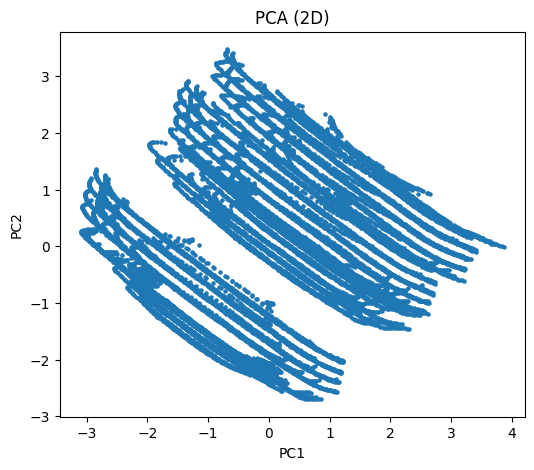

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], s=5)

plt.title("PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [15]:
from sklearn.cluster import KMeans

# try 4 clusters just as an example
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_pca_2d)

# check first 10 labels
kmeans_labels[:10]


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)

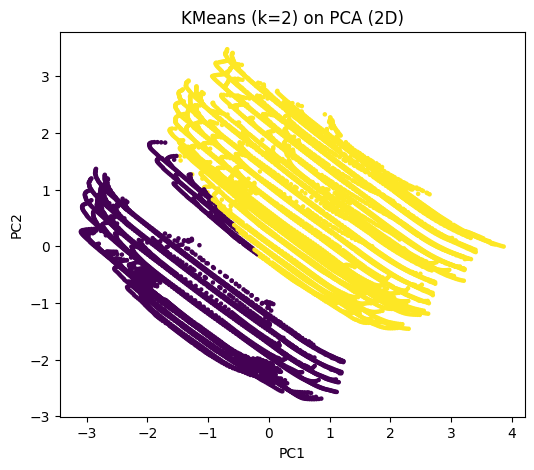

In [16]:
plt.figure(figsize=(6,5))
plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=kmeans_labels,
    s=5
)
plt.title("KMeans (k=2) on PCA (2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


In [17]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(X_pca_2d, kmeans_labels)
sil_score

0.39740380818477034

In [18]:
import pandas as pd

df_pca = pd.DataFrame({
    "PC1": X_pca_2d[:, 0],
    "PC2": X_pca_2d[:, 1]
})

df_pca.to_csv("../outputs/pca_2d_results.csv", index=False)


In [19]:
import umap.umap_ as umap

umap_2d = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

X_umap_2d = umap_2d.fit_transform(X_scaled)
X_umap_2d[:5]


array([[10.735788  , -0.03441888],
       [10.747912  , -0.02258946],
       [10.736029  , -0.02722012],
       [10.776228  , -0.09597464],
       [10.8881    , -0.31520596]], dtype=float32)

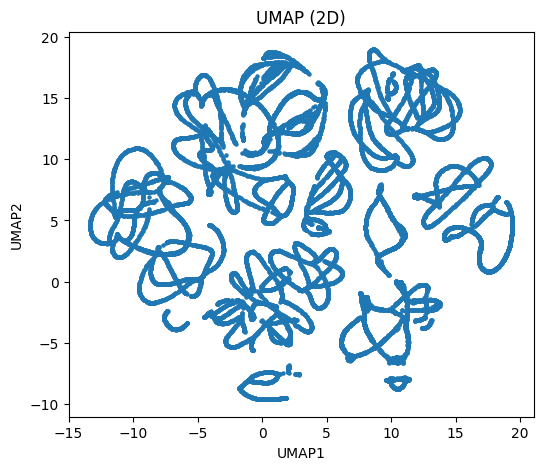

In [20]:
plt.figure(figsize=(6,5))
plt.scatter(X_umap_2d[:,0], X_umap_2d[:,1], s=5)
plt.title("UMAP (2D)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.show()


In [21]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=20)  # eps may need tweaking
dbscan_labels = dbscan.fit_predict(X_umap_2d)

# unique labels (clusters)
import numpy as np
np.unique(dbscan_labels)


array([ -1,   0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,
        12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,
        25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,
        38,  39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,
        51,  52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,
        64,  65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,
        77,  78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,
        90,  91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102,
       103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113])

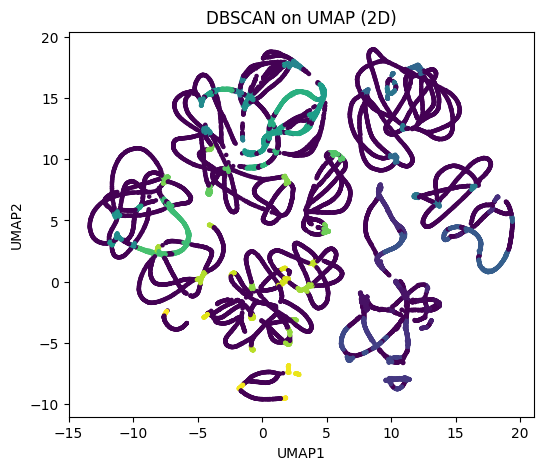

In [22]:
plt.figure(figsize=(6,5))
plt.scatter(
    X_umap_2d[:, 0],
    X_umap_2d[:, 1],
    c=dbscan_labels,
    s=5
)
plt.title("DBSCAN on UMAP (2D)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.show()


In [23]:
valid_mask = dbscan_labels != -1
if len(np.unique(dbscan_labels[valid_mask])) > 1:
    sil_dbscan = silhouette_score(X_umap_2d[valid_mask], dbscan_labels[valid_mask])
    sil_dbscan
else:
    sil_dbscan = None
sil_dbscan


0.5629557967185974

In [24]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    max_iter=1000,
    random_state=42
)

X_tsne_2d = tsne.fit_transform(X_scaled)
X_tsne_2d[:5]


array([[-58.415043, -22.440763],
       [-58.215256, -22.528187],
       [-57.983524, -22.608286],
       [-57.359657, -22.799013],
       [-55.316906, -23.430376]], dtype=float32)

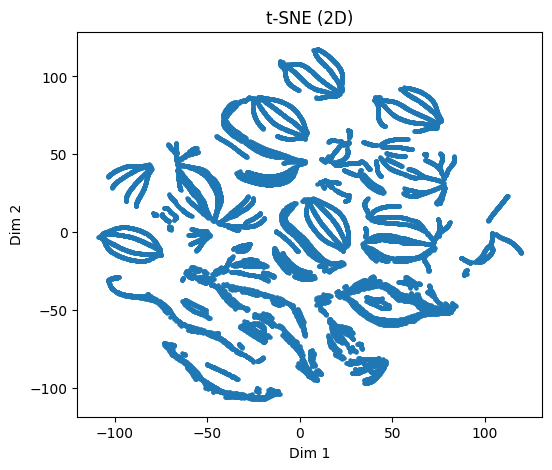

In [25]:
plt.figure(figsize=(6,5))
plt.scatter(X_tsne_2d[:,0], X_tsne_2d[:,1], s=5)
plt.title("t-SNE (2D)")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()
